In [2]:
%pip install requests beautifulsoup4 pandas matplotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: C:\Users\USER\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:

import requests
from bs4 import BeautifulSoup

import pandas as pd
import numpy as np
import re
import time
from pathlib import Path
from urllib.parse import urljoin

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from IPython.display import display

sns.set_theme(style="whitegrid")

Path("data").mkdir(parents=True, exist_ok=True)
Path("figures").mkdir(parents=True, exist_ok=True)
Path("report").mkdir(parents=True, exist_ok=True)

print("All required libraries imported successfully.")
print("Project folder:", Path.cwd())

All required libraries imported successfully.
Project folder: c:\Users\USER\OneDrive - Richfield Graduate Institute of Technology\DATA SCIENCE 512\402421893_DS500_ASSIGNMENT


In [4]:

from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

START_URL = "https://books.toscrape.com/catalogue/page-1.html"
TARGET_BOOKS = 1000

session = requests.Session()

session.headers.update({
    "User-Agent": "Mozilla/5.0 (compatible; StudentDataScienceProject/1.0)"
})

retry_strategy = Retry(
    total=5,
    backoff_factor=0.5,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"]
)

adapter = HTTPAdapter(max_retries=retry_strategy)
session.mount("https://", adapter)

Path("data").mkdir(parents=True, exist_ok=True)

RAW_FILE = Path("data/books_raw.csv")

columns = [
    "title",
    "price_gbp",
    "rating",
    "stock_status",
    "stock_quantity",
    "category",
    "description"
]

books = []
page_url = START_URL

def fetch_soup(url):
    response = session.get(url, timeout=30)
    response.encoding = "utf-8"
    response.raise_for_status()

    return BeautifulSoup(response.text, "html.parser")

while page_url and len(books) < TARGET_BOOKS:

    soup = fetch_soup(page_url)
    book_items = soup.select("article.product_pod")

    if not book_items:
        raise RuntimeError(
            f"No book listings found at {page_url}"
        )

    for item in book_items:

        title_element = item.select_one("h3 a")

        if title_element is None:
            continue

        title = title_element.get("title", "").strip()
        book_url = urljoin(page_url, title_element.get("href"))

        price_element = item.select_one(".price_color")

        if price_element is None:
            raise ValueError(f"Price not found for book: {title}")

        price_text = price_element.get_text(strip=True)
        price_match = re.search(r"\d+(?:\.\d+)?", price_text)

        if price_match is None:
            raise ValueError(f"Could not read price for: {title}")

        price = float(price_match.group())

        rating_element = item.select_one("p.star-rating")
        rating_classes = (
            rating_element.get("class", [])
            if rating_element else []
        )

        rating = next(
            (
                value.title()
                for value in rating_classes
                if value.lower() in
                ["one", "two", "three", "four", "five"]
            ),
            None
        )

        detail_soup = fetch_soup(book_url)

        breadcrumb_links = detail_soup.select(
            "ul.breadcrumb li a"
        )

        category = (
            breadcrumb_links[-1].get_text(strip=True)
            if len(breadcrumb_links) >= 3
            else None
        )

        description_heading = detail_soup.select_one(
            "#product_description"
        )

        description_element = (
            description_heading.find_next_sibling("p")
            if description_heading else None
        )

        description = (
            description_element.get_text(" ", strip=True)
            if description_element else None
        )

        availability_element = detail_soup.select_one(
            ".availability"
        )

        availability_text = (
            availability_element.get_text(" ", strip=True)
            if availability_element else ""
        )

        if re.search(r"\bout of stock\b", availability_text, re.I):
            stock_status = "Out of stock"
        elif re.search(r"\bin stock\b", availability_text, re.I):
            stock_status = "In stock"
        else:
            stock_status = "Unknown"

        quantity_match = re.search(
            r"\((\d+)\s+available\)",
            availability_text,
            re.I
        )

        stock_quantity = (
            int(quantity_match.group(1))
            if quantity_match else None
        )

        books.append({
            "title": title,
            "price_gbp": price,
            "rating": rating,
            "stock_status": stock_status,
            "stock_quantity": stock_quantity,
            "category": category,
            "description": description
        })

        if len(books) % 100 == 0:
            pd.DataFrame(books, columns=columns).to_csv(
                RAW_FILE,
                index=False,
                encoding="utf-8"
            )
            print(f"Collected {len(books)} of {TARGET_BOOKS} books.")

        if len(books) >= TARGET_BOOKS:
            break

        time.sleep(0.1)

    next_button = soup.select_one("li.next a")

    if next_button and len(books) < TARGET_BOOKS:
        page_url = urljoin(
            page_url,
            next_button.get("href")
        )
        time.sleep(0.2)
    else:
        page_url = None


df_raw = pd.DataFrame(books, columns=columns)

df_raw.to_csv(
    RAW_FILE,
    index=False,
    encoding="utf-8"
)


print("\nDATA ACQUISITION RESULTS")
print("Books collected:", len(df_raw))
print("Dataset shape:", df_raw.shape)
print("Target reached:", len(df_raw) == TARGET_BOOKS)

print("\nColumns:")
print(df_raw.columns.tolist())

print("\nRating counts:")
print(df_raw["rating"].value_counts(dropna=False))

print("\nStock status:")
print(df_raw["stock_status"].value_counts(dropna=False))

print("\nMissing values:")
print(df_raw.isnull().sum())

print("\nDuplicate rows:", df_raw.duplicated().sum())

print("\nFirst five books:")
display(df_raw.head())

print("\nRaw dataset saved to:", RAW_FILE.resolve())

Collected 100 of 1000 books.
Collected 200 of 1000 books.
Collected 300 of 1000 books.
Collected 400 of 1000 books.
Collected 500 of 1000 books.
Collected 600 of 1000 books.
Collected 700 of 1000 books.
Collected 800 of 1000 books.
Collected 900 of 1000 books.
Collected 1000 of 1000 books.

DATA ACQUISITION RESULTS
Books collected: 1000
Dataset shape: (1000, 7)
Target reached: True

Columns:
['title', 'price_gbp', 'rating', 'stock_status', 'stock_quantity', 'category', 'description']

Rating counts:
rating
One      226
Three    203
Five     196
Two      196
Four     179
Name: count, dtype: int64

Stock status:
stock_status
In stock    1000
Name: count, dtype: int64

Missing values:
title             0
price_gbp         0
rating            0
stock_status      0
stock_quantity    0
category          0
description       2
dtype: int64

Duplicate rows: 0

First five books:


,title,price_gbp,rating,stock_status,stock_quantity,category,description
0,A Light in the Attic,51.77,Three,In stock,22,Poetry,It's hard to imagine a world without A Light i...
1,Tipping the Velvet,53.74,One,In stock,20,Historical Fiction,"""Erotic and absorbing...Written with starling ..."
2,Soumission,50.10,One,In stock,20,Fiction,"Dans une France assez proche de la nôtre, un h..."
3,Sharp Objects,47.82,Four,In stock,20,Mystery,"WICKED above her hipbone, GIRL across her hear..."
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock,20,History,From a renowned historian comes a groundbreaki...



Raw dataset saved to: C:\Users\USER\OneDrive - Richfield Graduate Institute of Technology\DATA SCIENCE 512\402421893_DS500_ASSIGNMENT\data\books_raw.csv


In [5]:

from pathlib import Path
import pandas as pd
import re

raw_path = Path("data/books_raw.csv")
cleaned_path = Path("data/books_cleaned.csv")

if not raw_path.exists():
    raise FileNotFoundError(
        f"Raw dataset not found: {raw_path.resolve()}"
    )

df_raw = pd.read_csv(
    raw_path,
    encoding="utf-8"
)

print("Raw dataset loaded:", df_raw.shape)

df_cleaned = df_raw.copy()

text_columns = [
    "title",
    "rating",
    "stock_status",
    "category",
    "description"
]

for column in text_columns:
    df_cleaned[column] = df_cleaned[column].apply(
        lambda value: value.strip()
        if isinstance(value, str)
        else value
    )

df_cleaned["price_gbp"] = pd.to_numeric(
    df_cleaned["price_gbp"],
    errors="coerce"
)

df_cleaned["stock_quantity"] = pd.to_numeric(
    df_cleaned["stock_quantity"],
    errors="coerce"
).astype("Int64")

rating_mapping = {
    "one": "One",
    "two": "Two",
    "three": "Three",
    "four": "Four",
    "five": "Five"
}

df_cleaned["rating"] = (
    df_cleaned["rating"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map(rating_mapping)
)

numeric_rating_mapping = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

df_cleaned["rating_score"] = (
    df_cleaned["rating"].map(numeric_rating_mapping)
)

stock_mapping = {
    "in stock": "In stock",
    "out of stock": "Out of stock",
    "unknown": "Unknown"
}

df_cleaned["stock_status"] = (
    df_cleaned["stock_status"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map(stock_mapping)
)

df_cleaned["category"] = (
    df_cleaned["category"].astype("string").str.strip()
)

invalid_categories = ["default", "add a comment"]

invalid_mask = (
    df_cleaned["category"]
    .str.lower()
    .isin(invalid_categories)
)

invalid_count = int(invalid_mask.sum())

df_cleaned.loc[
    invalid_mask, "category"
] = "Uncategorised"

df_cleaned["category"] = (
    df_cleaned["category"].fillna("Uncategorised")
)

df_cleaned["description_available"] = (
    df_cleaned["description"].apply(
        lambda value: (
            isinstance(value, str) and bool(value.strip())
        )
    )
)

df_cleaned["description"] = df_cleaned["description"].apply(
    lambda value: re.sub(r"\s+", " ", value).strip()
    if isinstance(value, str)
    else ""
)

rows_before = len(df_cleaned)

df_cleaned = df_cleaned.dropna(
    subset=[
        "title",
        "price_gbp",
        "rating",
        "rating_score",
        "stock_status"
    ]
).copy()

rows_removed = rows_before - len(df_cleaned)

invalid_price_rows = int(
    (df_cleaned["price_gbp"] <= 0).sum()
)

df_cleaned = df_cleaned[
    df_cleaned["price_gbp"] > 0
].copy()

duplicates_removed = int(df_cleaned.duplicated().sum())
df_cleaned = df_cleaned.drop_duplicates().copy()

df_cleaned.to_csv(
    cleaned_path,
    index=False,
    encoding="utf-8"
)

print("\nCLEANING RESULTS")
print("Raw rows:", len(df_raw))
print("Cleaned rows:", len(df_cleaned))
print("Cleaned shape:", df_cleaned.shape)
print("Rows removed for missing essential fields:", rows_removed)
print("Invalid-price rows removed:", invalid_price_rows)
print("Duplicate rows removed:", duplicates_removed)
print("Invalid category values recoded:", invalid_count)

print("\nMissing values after cleaning:")
print(df_cleaned.isnull().sum())

print("\nCategory counts:")
print(df_cleaned["category"].value_counts().head(15))

print("\nRating counts:")
print(df_cleaned["rating"].value_counts())

print("\nPrice summary:")
print(df_cleaned["price_gbp"].describe())

print("\nDescriptions available:")
print(df_cleaned["description_available"].value_counts())

print("\nCleaned dataset saved to:")
print(cleaned_path.resolve())

display(df_cleaned.head())

print("\nDATA CLEANING COMPLETE")

Raw dataset loaded: (1000, 7)

CLEANING RESULTS
Raw rows: 1000
Cleaned rows: 1000
Cleaned shape: (1000, 9)
Rows removed for missing essential fields: 0
Invalid-price rows removed: 0
Duplicate rows removed: 0
Invalid category values recoded: 219

Missing values after cleaning:
title                    0
price_gbp                0
rating                   0
stock_status             0
stock_quantity           0
category                 0
description              0
rating_score             0
description_available    0
dtype: int64

Category counts:
category
Uncategorised         219
Nonfiction            110
Sequential Art         75
Fiction                65
Young Adult            54
Fantasy                48
Romance                35
Mystery                32
Food and Drink         30
Childrens              29
Historical Fiction     26
Poetry                 19
Classics               19
History                18
Horror                 17
Name: count, dtype: Int64

Rating counts:
rating
O

,title,price_gbp,rating,stock_status,stock_quantity,category,description,rating_score,description_available
0,A Light in the Attic,51.77,Three,In stock,22,Poetry,It's hard to imagine a world without A Light i...,3,True
1,Tipping the Velvet,53.74,One,In stock,20,Historical Fiction,"""Erotic and absorbing...Written with starling ...",1,True
2,Soumission,50.10,One,In stock,20,Fiction,"Dans une France assez proche de la nôtre, un h...",1,True
3,Sharp Objects,47.82,Four,In stock,20,Mystery,"WICKED above her hipbone, GIRL across her hear...",4,True
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock,20,History,From a renowned historian comes a groundbreaki...,5,True



DATA CLEANING COMPLETE


Dataset shape: (1000, 9)
Number of categories: 49


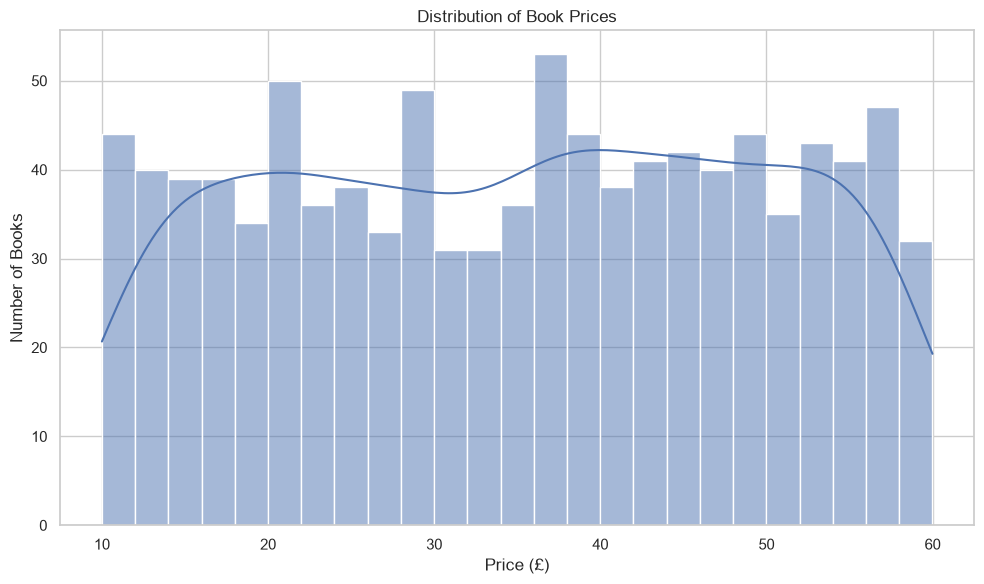

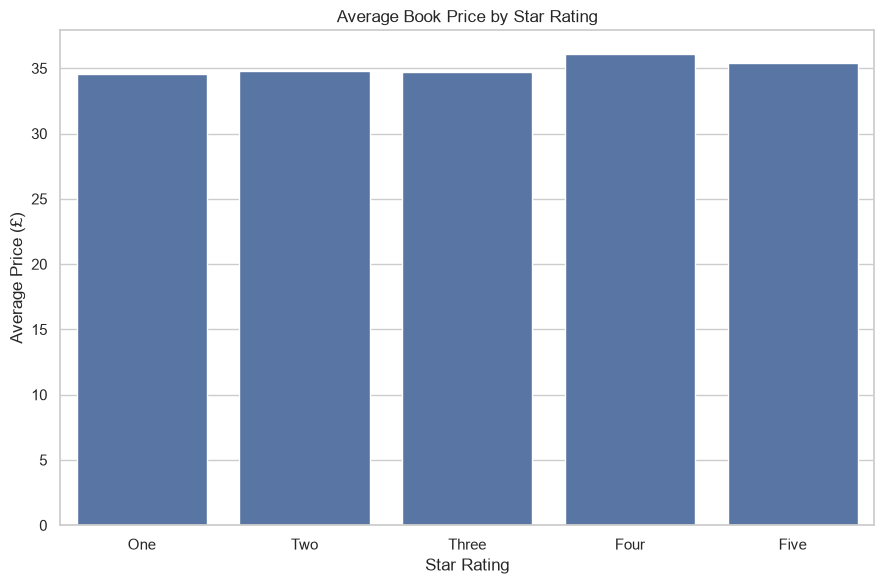

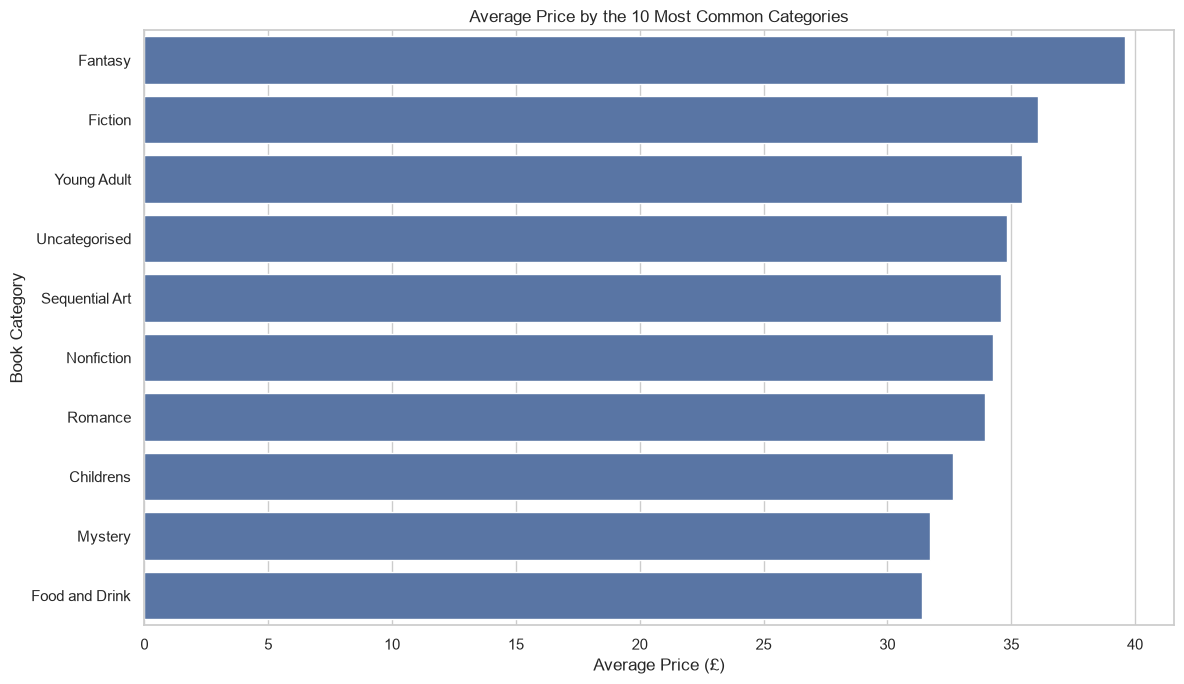

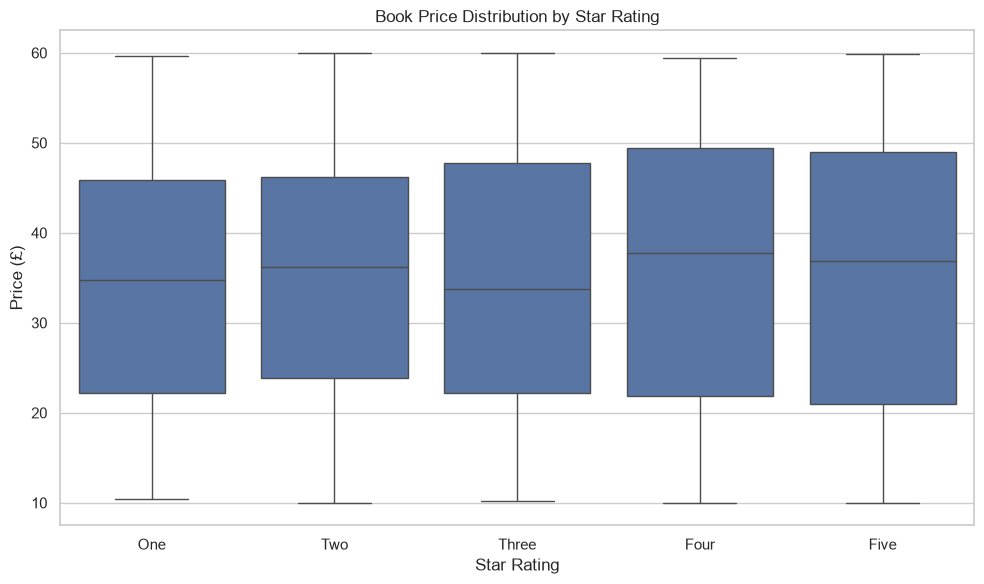

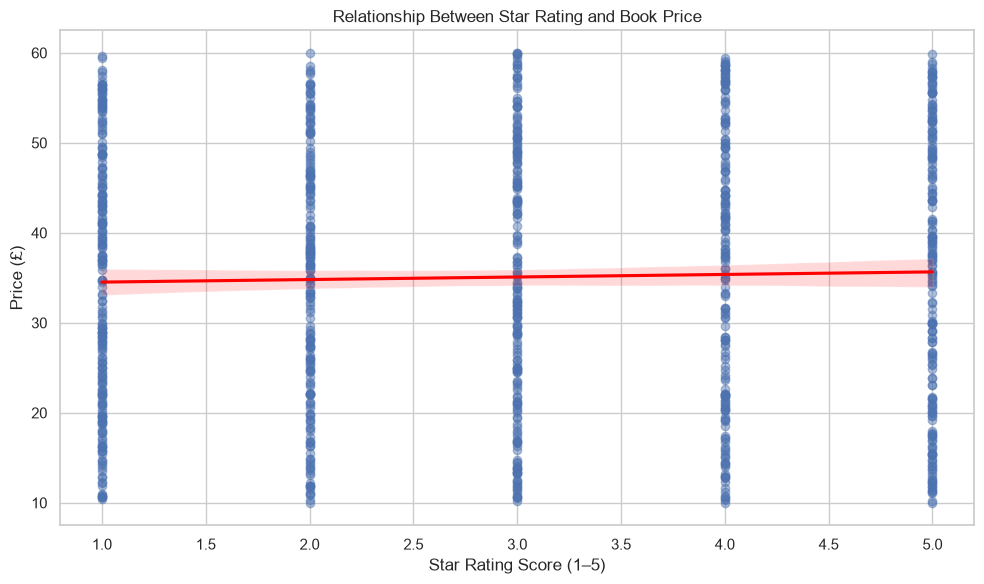


PRICE SUMMARY
count    1000.00
mean       35.07
std        14.45
min        10.00
25%        22.11
50%        35.98
75%        47.46
max        59.99
Name: price_gbp, dtype: float64

AVERAGE PRICE BY STAR RATING


,book_count,average_price,median_price
rating,,,
One,226,34.56,34.77
Two,196,34.81,36.22
Three,203,34.69,33.78
Four,179,36.09,37.80
Five,196,35.37,36.90



AVERAGE PRICE BY TOP CATEGORIES


,book_count,average_price,median_price
category,,,
Fantasy,48,39.59,43.58
Fiction,65,36.07,39.72
Young Adult,54,35.45,36.61
Uncategorised,219,34.82,36.05
Sequential Art,75,34.57,36.52
Nonfiction,110,34.26,32.15
Romance,35,33.93,34.53
Childrens,29,32.64,28.54
Mystery,32,31.72,25.38



RATING-PRICE CORRELATION
Correlation: 0.028

STOCK STATUS COUNTS
stock_status
In stock    1000
Name: count, dtype: int64

VISUALISATIONS SAVED
figures/price_distribution.png
figures/average_price_by_rating.png
figures/average_price_by_category.png
figures/price_by_rating_boxplot.png
figures/rating_price_relationship.png


In [6]:

from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

Path("figures").mkdir(parents=True, exist_ok=True)

print("Dataset shape:", df_cleaned.shape)
print("Number of categories:", df_cleaned["category"].nunique())

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_cleaned,
    x="price_gbp",
    bins=25,
    kde=True
)

plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")
plt.tight_layout()

plt.savefig(
    "figures/price_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

rating_order = ["One", "Two", "Three", "Four", "Five"]

plt.figure(figsize=(9, 6))

sns.barplot(
    data=df_cleaned,
    x="rating",
    y="price_gbp",
    order=rating_order,
    errorbar=None
)

plt.title("Average Book Price by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Average Price (£)")
plt.tight_layout()

plt.savefig(
    "figures/average_price_by_rating.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

top_categories = (
    df_cleaned["category"]
    .value_counts()
    .head(10)
    .index
)

category_data = df_cleaned[
    df_cleaned["category"].isin(top_categories)
]

category_average_prices = (
    category_data.groupby("category")["price_gbp"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=category_average_prices.values,
    y=category_average_prices.index,
    errorbar=None
)

plt.title("Average Price by the 10 Most Common Categories")
plt.xlabel("Average Price (£)")
plt.ylabel("Book Category")
plt.tight_layout()

plt.savefig(
    "figures/average_price_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_cleaned,
    x="rating",
    y="price_gbp",
    order=rating_order
)

plt.title("Book Price Distribution by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Price (£)")
plt.tight_layout()

plt.savefig(
    "figures/price_by_rating_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_cleaned,
    x="rating_score",
    y="price_gbp",
    scatter_kws={"alpha": 0.45},
    line_kws={"color": "red"}
)

plt.title("Relationship Between Star Rating and Book Price")
plt.xlabel("Star Rating Score (1–5)")
plt.ylabel("Price (£)")
plt.tight_layout()

plt.savefig(
    "figures/rating_price_relationship.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nPRICE SUMMARY")
print(df_cleaned["price_gbp"].describe().round(2))

print("\nAVERAGE PRICE BY STAR RATING")

rating_summary = (
    df_cleaned.groupby("rating")
    .agg(
        book_count=("title", "count"),
        average_price=("price_gbp", "mean"),
        median_price=("price_gbp", "median")
    )
    .reindex(rating_order)
)

display(rating_summary.round(2))

print("\nAVERAGE PRICE BY TOP CATEGORIES")

category_summary = (
    category_data.groupby("category")
    .agg(
        book_count=("title", "count"),
        average_price=("price_gbp", "mean"),
        median_price=("price_gbp", "median")
    )
    .sort_values("average_price", ascending=False)
)

display(category_summary.round(2))

print("\nRATING-PRICE CORRELATION")

correlation = df_cleaned[
    ["rating_score", "price_gbp"]
].corr().loc["rating_score", "price_gbp"]

print("Correlation:", round(correlation, 3))

print("\nSTOCK STATUS COUNTS")
print(df_cleaned["stock_status"].value_counts())

print("\nVISUALISATIONS SAVED")
print("figures/price_distribution.png")
print("figures/average_price_by_rating.png")
print("figures/average_price_by_category.png")
print("figures/price_by_rating_boxplot.png")
print("figures/rating_price_relationship.png")

In [7]:

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

df_model = pd.read_csv(
    "data/books_cleaned.csv",
    encoding="utf-8"
)

print("CLEANED DATASET")
print("Dataset shape:", df_model.shape)

required_columns = [
    "price_gbp",
    "rating_score",
    "stock_quantity",
    "category",
    "description_available"
]

missing_columns = [
    column for column in required_columns
    if column not in df_model.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

for column in [
    "price_gbp",
    "rating_score",
    "stock_quantity"
]:
    df_model[column] = pd.to_numeric(
        df_model[column],
        errors="coerce"
    )

df_model["description_available"] = (
    df_model["description_available"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "true": 1,
        "false": 0,
        "1": 1,
        "0": 0
    })
)

df_model = df_model.dropna(
    subset=required_columns
).copy()

df_model = df_model[
    (df_model["price_gbp"] > 0)
    & df_model["rating_score"].between(1, 5)
].copy()

numeric_features = [
    "rating_score",
    "stock_quantity",
    "description_available"
]

categorical_features = ["category"]

X = df_model[numeric_features + categorical_features]
y = df_model["price_gbp"]

print("\nMODELLING DATA")
print("Usable books:", len(df_model))
print("Target variable: price_gbp")
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTRAIN-TEST SPLIT")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            numeric_features
        ),
        (
            "category",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_features
        )
    ]
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regression", LinearRegression())
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

baseline_predictions = np.full(
    len(y_test),
    y_train.mean()
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_predictions
    )
)

baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)

metrics = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Training Mean Baseline"
    ],
    "MAE_GBP": [
        mae,
        baseline_mae
    ],
    "RMSE_GBP": [
        rmse,
        baseline_rmse
    ],
    "R_squared": [
        r2,
        baseline_r2
    ]
})

print("\nMODEL EVALUATION")
display(metrics.round(4))

print("\nINTERPRETATION")
print(f"MAE: £{mae:.2f}")
print(f"RMSE: £{rmse:.2f}")
print(f"R-squared: {r2:.4f}")
print(f"R-squared percentage: {r2 * 100:.2f}%")

if r2 > 0:
    print(
        "The model explains a proportion of the variation "
        "in test-set book prices."
    )
else:
    print(
        "The model does not explain positive variation "
        "in test-set book prices relative to the test-set mean."
    )

if mae < baseline_mae:
    print(
        "The regression model has a lower MAE than the baseline."
    )
else:
    print(
        "The regression model does not improve on baseline MAE."
    )

Path("report").mkdir(
    parents=True,
    exist_ok=True
)

metrics.to_csv(
    "report/regression_metrics.csv",
    index=False,
    encoding="utf-8"
)

predictions = pd.DataFrame({
    "actual_price_gbp": y_test,
    "predicted_price_gbp": y_pred
})

predictions["residual_gbp"] = (
    predictions["actual_price_gbp"]
    - predictions["predicted_price_gbp"]
)

predictions.to_csv(
    "data/regression_predictions.csv",
    index_label="original_index",
    encoding="utf-8"
)

print("\nSAVED FILES")
print("report/regression_metrics.csv")
print("data/regression_predictions.csv")
print("\nREGRESSION COMPLETE")

CLEANED DATASET
Dataset shape: (1000, 9)

MODELLING DATA
Usable books: 1000
Target variable: price_gbp
Numeric features: ['rating_score', 'stock_quantity', 'description_available']
Categorical features: ['category']

TRAIN-TEST SPLIT
Training records: 800
Testing records: 200

MODEL EVALUATION


C:\Users\USER\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,Model,MAE_GBP,RMSE_GBP,R_squared
0,Linear Regression,13.0138,15.2082,-0.1010
1,Training Mean Baseline,12.6619,14.5305,-0.0051



INTERPRETATION
MAE: £13.01
RMSE: £15.21
R-squared: -0.1010
R-squared percentage: -10.10%
The model does not explain positive variation in test-set book prices relative to the test-set mean.
The regression model does not improve on baseline MAE.

SAVED FILES
report/regression_metrics.csv
data/regression_predictions.csv

REGRESSION COMPLETE


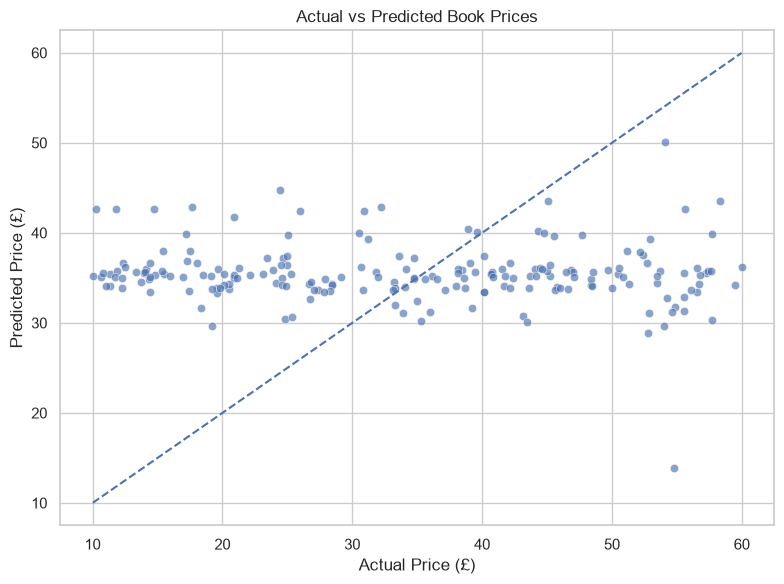

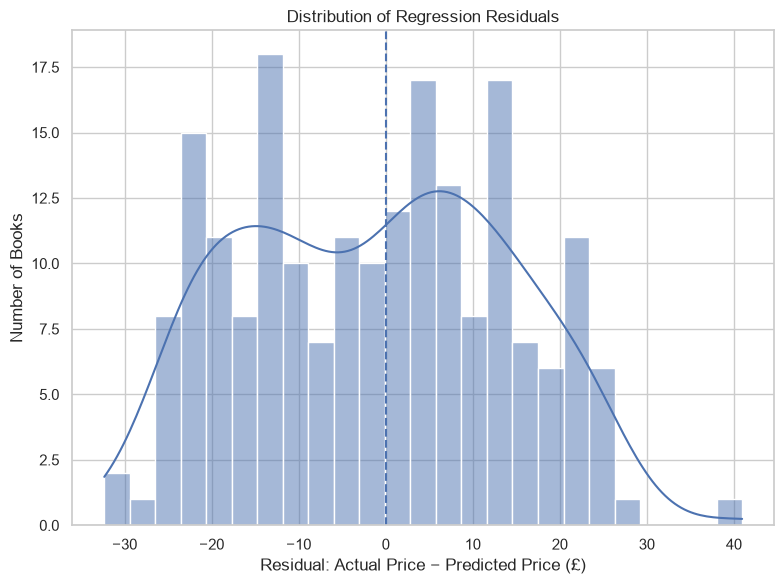

RESIDUAL SUMMARY
count    200.00
mean      -1.22
std       15.20
min      -32.34
25%      -14.08
50%       -0.21
75%       11.02
max       40.94
Name: residual_gbp, dtype: float64

Diagnostic charts saved:
figures/actual_vs_predicted.png
figures/regression_residuals.png


In [8]:

from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

Path("figures").mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=predictions["actual_price_gbp"],
    y=predictions["predicted_price_gbp"],
    alpha=0.65
)

lower = min(
    predictions["actual_price_gbp"].min(),
    predictions["predicted_price_gbp"].min()
)

upper = max(
    predictions["actual_price_gbp"].max(),
    predictions["predicted_price_gbp"].max()
)

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

plt.title("Actual vs Predicted Book Prices")
plt.xlabel("Actual Price (£)")
plt.ylabel("Predicted Price (£)")
plt.tight_layout()

plt.savefig(
    "figures/actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.figure(figsize=(8, 6))

sns.histplot(
    data=predictions,
    x="residual_gbp",
    bins=25,
    kde=True
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.title("Distribution of Regression Residuals")
plt.xlabel("Residual: Actual Price − Predicted Price (£)")
plt.ylabel("Number of Books")
plt.tight_layout()

plt.savefig(
    "figures/regression_residuals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("RESIDUAL SUMMARY")
print(predictions["residual_gbp"].describe().round(2))

print("\nDiagnostic charts saved:")
print("figures/actual_vs_predicted.png")
print("figures/regression_residuals.png")